# 10 Evaluation and calibration (Phase 1 vs Phase 2)

The fair comparison asked for in the brief: same features, same decision time, same date split, same
metrics as Phase 1. The Phase 1 numbers are read from the Phase 1 prediction files, not retrained, so the
baselines are exactly the ones in the Phase 1 report.

* Discrimination: PR-AUC (headline, imbalanced target), ROC-AUC.
* Calibration: Brier score, log loss, ECE (10 equal-width bins), reliability diagram.
* Operating point: threshold chosen on validation for precision >= 0.5 with the highest recall, then
  applied unchanged to December.
* Uncertainty: paired bootstrap over **days** of December for the PR-AUC difference to XGBoost.

This notebook also writes every table, figure (PDF) and number used by the report and the slides.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss,
                             precision_recall_curve, roc_auc_score, roc_curve)

In [2]:
from pathlib import Path

PHASE1_ROOT = Path("../..").resolve()
ROOT = Path("..").resolve()
PHASE1_DATA = PHASE1_ROOT / "data" / "processed"
PHASE1_RESULTS = PHASE1_ROOT / "results"
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
TABLE_DIR = RESULTS_DIR / "tables"
for d in (FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET_PRECISION = 0.5
ROLL_WINDOWS = (7, 14, 28)
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False})

## Load predictions

Phase 1 files hold the prior rate, route-history baseline, LR and XGBoost (raw, Platt-calibrated and rolling
recalibrated). Phase 2 files hold the networks from notebooks 07 and 08.

In [3]:
preds = {}
for s in ("val", "test"):
    p1 = pd.read_pickle(PHASE1_DATA / f"predictions_{s}.pkl")
    p2 = pd.read_pickle(PROCESSED_DIR / f"dl_predictions_{s}.pkl")
    assert np.array_equal(p1["id"].to_numpy(), p2["id"].to_numpy())
    preds[s] = pd.concat([p1, p2.drop(columns="id")], axis=1)
val, test = preds["val"], preds["test"]

with open(RESULTS_DIR / "hybrid_selected.json") as f:
    hybrid_info = json.load(f)
with open(RESULTS_DIR / "dl_selected.json") as f:
    dl_info = json.load(f)
FINAL_NAME, FINAL_COL = hybrid_info["final_model"], hybrid_info["final_column"]

PHASE2 = {"Embedding MLP": "p_mlp", "Temporal (MLP+GRU)": "p_temporal",
          "Leaf hybrid": "p_leaf_hybrid", "Blend": "p_blend"}
SHORT = {"p_mlp": "Embedding MLP", "p_temporal": "Temporal (MLP+GRU)", "p_leaf_hybrid": "Leaf hybrid",
         "p_blend": "Blend"}
FINAL = SHORT[FINAL_COL]
print("final Phase 2 model (chosen on validation in notebook 08):", FINAL)
len(val), len(test)

final Phase 2 model (chosen on validation in notebook 08): Temporal (MLP+GRU)


(55589, 27020)

## Metric functions (same definitions as Phase 1 notebook 04)

In [4]:
def expected_calibration_error(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    ece = 0.0
    for b in range(bins):
        mask = idx == b
        if mask.any():
            ece += mask.mean() * abs(p[mask].mean() - y[mask].mean())
    return ece


def threshold_for_precision(y, p, target):
    """Lowest threshold whose precision is >= target (=> highest recall at that precision)."""
    precision, recall, thresholds = precision_recall_curve(y, p)
    ok = np.where(precision[:-1] >= target)[0]
    if len(ok) == 0:
        return None
    best = ok[np.argmax(recall[ok])]
    return float(thresholds[best])


def recall_at_precision(y, p, target):
    precision, recall, _ = precision_recall_curve(y, p)
    ok = precision >= target
    return float(recall[ok].max()) if ok.any() else 0.0


def score(y, p):
    return {"pr_auc": average_precision_score(y, p),
            "roc_auc": roc_auc_score(y, p) if np.unique(p).size > 1 else 0.5,
            "brier": brier_score_loss(y, p),
            "log_loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)),
            "ece": expected_calibration_error(y, p),
            "mean_pred": float(np.mean(p))}

## Calibration of the Phase 2 models

Three candidates, all fitted on validation scores:

* **Temperature scaling** (Guo et al., 2017): $p = \sigma(z / T)$ with a single parameter $T$ fitted by
  log loss. It changes confidence but not the ranking. This is the standard fix for neural networks.
* **Platt scaling**: $p = \sigma(a z + b)$, one more parameter, can also shift the base rate.
* **Isotonic regression**: monotone step function.

Chosen exactly like Phase 1: fit on October and score Brier on November, and the other way round; the
method with the lower mean Brier is refitted on all of Oct-Nov. Then, as in Phase 1, a **rolling Platt**
recalibration refits every day on the previous $w$ days of (out-of-sample) scores and outcomes, because
December has almost twice the delay rate of Oct-Nov. The window $w$ is chosen on November.

In [5]:
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


class Calibrator:
    def __init__(self, method):
        self.method = method

    def fit(self, p, y):
        z = logit(p)
        if self.method == "temperature":
            nll = lambda log_t: log_loss(y, 1 / (1 + np.exp(-z / np.exp(log_t))))
            self.T = float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))
        elif self.method == "platt":
            self.model = LogisticRegression(C=1e6).fit(z[:, None], y)
        else:
            self.model = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p, y)
        return self

    def predict(self, p):
        if self.method == "temperature":
            return 1 / (1 + np.exp(-logit(p) / self.T))
        if self.method == "platt":
            return self.model.predict_proba(logit(p)[:, None])[:, 1]
        return self.model.predict(p)


def choose_calibrator(p, y, month):
    scores = {}
    for method in ("temperature", "platt", "isotonic"):
        briers = []
        for fit_m, eval_m in ((10, 11), (11, 10)):
            cal = Calibrator(method).fit(p[month == fit_m], y[month == fit_m])
            briers.append(brier_score_loss(y[month == eval_m], cal.predict(p[month == eval_m])))
        scores[method] = float(np.mean(briers))
    best = min(scores, key=scores.get)
    return Calibrator(best).fit(p, y), scores


def rolling_calibrate(history, target, col, window):
    out = target[col].to_numpy().copy()   # days without usable history keep the raw score
    for d in target["date"].unique():
        past = history[(history["date"] < d) & (history["date"] >= d - pd.Timedelta(days=window))]
        if past["delayed"].nunique() < 2:
            continue
        cal = Calibrator("platt").fit(past[col].to_numpy(), past["delayed"].to_numpy())
        idx = (target["date"] == d).to_numpy()
        out[idx] = cal.predict(out[idx])
    return out


yv, yt = val["delayed"].to_numpy(), test["delayed"].to_numpy()
history = pd.concat([val, test], ignore_index=True)
november = val[val["month"] == 11]
cal_rows, roll_choice = [], {}
for name, col in PHASE2.items():
    cal, scores = choose_calibrator(val[col].to_numpy(), yv, val["month"].to_numpy())
    val[f"{col}_cal"] = cal.predict(val[col].to_numpy())
    test[f"{col}_cal"] = cal.predict(test[col].to_numpy())
    briers = {w: brier_score_loss(november["delayed"], rolling_calibrate(val, november, col, w))
              for w in ROLL_WINDOWS}
    w = min(briers, key=briers.get)
    roll_choice[col] = w
    test[f"{col}_roll"] = rolling_calibrate(history, test, col, w)
    val[f"{col}_roll"] = rolling_calibrate(history, val, col, w)
    cal_rows.append({"model": name, "method": cal.method, **{f"cv_brier_{k}": v for k, v in scores.items()},
                     "temperature": getattr(cal, "T", np.nan), "roll_window": w})
cal_choice = pd.DataFrame(cal_rows)
cal_choice.round(5)

,model,method,cv_brier_temperature,cv_brier_platt,cv_brier_isotonic,temperature,roll_window
0,Embedding MLP,platt,0.14171,0.13926,0.13935,NaN,28
1,Temporal (MLP+GRU),platt,0.14445,0.13913,0.13953,NaN,28
2,Leaf hybrid,platt,0.14410,0.13955,0.13955,NaN,28
3,Blend,platt,0.14111,0.13970,0.13975,NaN,28


## All metrics

In [6]:
MODELS = {"Prior rate": "p_prior", "Route history": "p_hist_route",
          "LR": "p_lr_raw", "XGBoost": "p_xgb_raw", **PHASE2}
CAL_SUFFIX = {"raw": "", "cal": "_cal", "roll": "_roll"}
PHASE1_COLS = {"p_lr_raw": "p_lr", "p_xgb_raw": "p_xgb"}

rows = []
for name, col in MODELS.items():
    for kind, suffix in CAL_SUFFIX.items():
        if col in ("p_prior", "p_hist_route") and kind != "raw":
            continue
        c = PHASE1_COLS.get(col, col)
        c = col if kind == "raw" else c + suffix
        pv, pt = val[c].to_numpy(), test[c].to_numpy()
        row = {"model": name, "phase": 2 if col in PHASE2.values() else 1, "probabilities": kind}
        row.update({f"val_{k}": v for k, v in score(yv, pv).items()})
        row.update({f"test_{k}": v for k, v in score(yt, pt).items()})
        thr = threshold_for_precision(yv, pv, TARGET_PRECISION) if col not in ("p_prior", "p_hist_route") else None
        if thr is not None:
            flagged = pt >= thr
            row.update({"threshold": thr, "test_flagged": int(flagged.sum()),
                        "test_precision_at_thr": yt[flagged].mean() if flagged.any() else np.nan,
                        "test_recall_at_thr": flagged[yt == 1].mean()})
        row["test_recall_at_p50"] = recall_at_precision(yt, pt, TARGET_PRECISION)
        rows.append(row)

metrics = pd.DataFrame(rows)
metrics.to_csv(RESULTS_DIR / "metrics_phase2.csv", index=False)
show = ["model", "probabilities", "val_pr_auc", "test_pr_auc", "test_roc_auc", "test_brier", "test_ece",
        "test_recall_at_p50"]
metrics[show].round(4)

,model,probabilities,val_pr_auc,test_pr_auc,test_roc_auc,test_brier,test_ece,test_recall_at_p50
0,Prior rate,raw,0.1782,0.3355,0.5000,0.2303,0.0857,0.0000
1,Route history,raw,0.2132,0.3814,0.5535,0.2301,0.0955,0.0168
2,LR,raw,0.2975,0.4610,0.6401,0.2159,0.0640,0.2760
3,LR,cal,0.2975,0.4610,0.6401,0.2218,0.1034,0.2760
4,LR,roll,0.2798,0.4411,0.6192,0.2168,0.0450,0.2076
5,XGBoost,raw,0.2755,0.4683,0.6452,0.2163,0.0734,0.2918
6,XGBoost,cal,0.2755,0.4683,0.6452,0.2205,0.1017,0.2918
7,XGBoost,roll,0.2607,0.4505,0.6294,0.2150,0.0474,0.2467
8,Embedding MLP,raw,0.2931,0.4973,0.6611,0.2121,0.0695,0.4031
9,Embedding MLP,cal,0.2931,0.4973,0.6611,0.2207,0.1177,0.4031


Check that the Phase 1 rows are identical to the Phase 1 results file (nothing was retrained).

In [7]:
p1 = pd.read_csv(PHASE1_RESULTS / "metrics.csv").set_index("model")
mine = metrics[metrics["probabilities"] == "cal"].set_index("model")
for model in ("LR", "XGBoost"):
    assert np.isclose(p1.loc[model, "test_pr_auc"], mine.loc[model, "test_pr_auc"])
    assert np.isclose(p1.loc[model, "test_ece"], mine.loc[model, "test_ece"])
print("Phase 1 numbers reproduced exactly")

Phase 1 numbers reproduced exactly


## Seed stability

Spread over seeds 42/43/44 for each network (from notebooks 07 and 08). If the gap to XGBoost is larger than
this spread, it is not an accident of one initialisation.

In [8]:
seed_runs = pd.concat([pd.read_csv(RESULTS_DIR / "dl_seed_runs.csv"), pd.read_csv(RESULTS_DIR / "hybrid_seed_runs.csv")])
seed_summary = seed_runs.groupby("model", sort=False)[["val_pr_auc", "test_pr_auc"]].agg(["mean", "std", "min", "max"])
seed_summary.round(4)

val_pr_auc                         test_pr_auc                  \
                  mean     std     min     max        mean     std     min   
model                                                                        
MLP             0.2914  0.0021  0.2891  0.2931      0.4969  0.0010  0.4958   
Temporal        0.2936  0.0039  0.2905  0.2980      0.4993  0.0099  0.4881   
Leaf hybrid     0.2913  0.0027  0.2891  0.2942      0.4939  0.0039  0.4905   

                     
                max  
model                
MLP          0.4977  
Temporal     0.5068  
Leaf hybrid  0.4982

## Paired day-level bootstrap on December

Flights on the same day share weather and are strongly correlated, so resampling single flights would
give intervals that are far too narrow. We resample whole **days** (31 per replicate, with replacement)
and compute the PR-AUC difference to XGBoost on the same resampled days. 2,000 replicates.

In [9]:
def day_bootstrap(a, b, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    groups = list(test.groupby("date").indices.values())
    diffs = []
    for _ in range(n_boot):
        idx = np.concatenate([groups[j] for j in rng.integers(0, len(groups), len(groups))])
        diffs.append(average_precision_score(yt[idx], test[a].to_numpy()[idx])
                     - average_precision_score(yt[idx], test[b].to_numpy()[idx]))
    diffs = np.array(diffs)
    return {"diff": average_precision_score(yt, test[a]) - average_precision_score(yt, test[b]),
            "ci_low": np.quantile(diffs, 0.025), "ci_high": np.quantile(diffs, 0.975),
            "share_positive": (diffs > 0).mean()}


pairs = [(f"{n} - XGBoost", c, "p_xgb_raw") for n, c in PHASE2.items()]
pairs += [("Temporal - Embedding MLP", "p_temporal", "p_mlp"), ("Leaf hybrid - Temporal", "p_leaf_hybrid", "p_temporal")]
boot = pd.DataFrame([{"comparison": n, **day_bootstrap(a, b)} for n, a, b in pairs])
boot.to_csv(RESULTS_DIR / "bootstrap_pr_auc.csv", index=False)
boot.round(4)

,comparison,diff,ci_low,ci_high,share_positive
0,Embedding MLP - XGBoost,0.0290,0.0091,0.0453,0.9995
1,Temporal (MLP+GRU) - XGBoost,0.0347,0.0057,0.0581,0.9925
2,Leaf hybrid - XGBoost,0.0299,0.0087,0.0485,0.9995
3,Blend - XGBoost,0.0174,0.0062,0.0250,1.0000
4,Temporal - Embedding MLP,0.0057,-0.0097,0.0209,0.7630
5,Leaf hybrid - Temporal,-0.0048,-0.0171,0.0107,0.2555


## Figures (saved as PDF for the report)

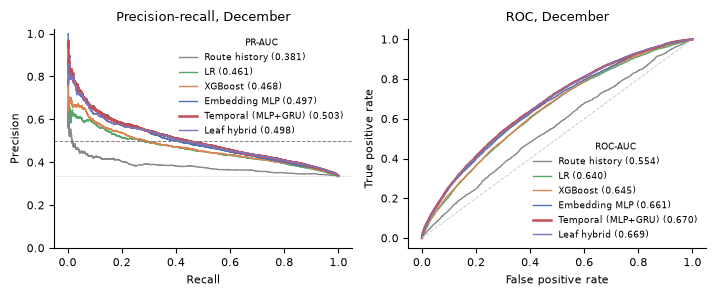

In [10]:
COLORS = {"Prior rate": "#BBBBBB", "Route history": "#888888", "LR": "#55A868", "XGBoost": "#DD8452",
          "Embedding MLP": "#4C72B0", "Temporal (MLP+GRU)": "#C44E52", "Leaf hybrid": "#8172B3", "Blend": "#937860"}
CURVES = ["Route history", "LR", "XGBoost", "Embedding MLP", "Temporal (MLP+GRU)", "Leaf hybrid"]

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
for name in CURVES:
    col = MODELS[name]
    p, r, _ = precision_recall_curve(yt, test[col])
    n_flagged = np.divide(r * yt.sum(), p, out=np.zeros_like(r), where=p > 0)
    keep = n_flagged >= 20
    lw = 1.8 if name == FINAL else 1.0
    axes[0].plot(r[keep], p[keep], color=COLORS[name], lw=lw, label=f"{name} ({average_precision_score(yt, test[col]):.3f})")
    fpr, tpr, _ = roc_curve(yt, test[col])
    axes[1].plot(fpr, tpr, color=COLORS[name], lw=lw, label=f"{name} ({roc_auc_score(yt, test[col]):.3f})")
axes[0].axhline(TARGET_PRECISION, color="0.5", lw=0.7, ls="--")
axes[0].axhline(yt.mean(), color="0.8", lw=0.7, ls=":")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall, December", ylim=(0, 1.02))
axes[1].plot([0, 1], [0, 1], color="0.8", lw=0.7, ls="--")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC, December")
axes[0].legend(title="PR-AUC", fontsize=6.5, title_fontsize=6.5, frameon=False)
axes[1].legend(title="ROC-AUC", fontsize=6.5, title_fontsize=6.5, frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "pr_roc_test.pdf")
plt.show()

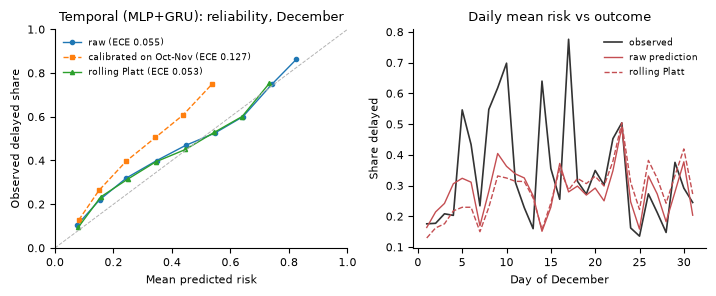

In [11]:
def reliability(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    out = [(p[idx == b].mean(), y[idx == b].mean(), (idx == b).sum()) for b in range(bins) if (idx == b).sum() >= 30]
    return np.array(out)


fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
final_col = PHASE2[FINAL]
for label, c, style in (("raw", final_col, "o-"), ("calibrated on Oct-Nov", f"{final_col}_cal", "s--"),
                        ("rolling Platt", f"{final_col}_roll", "^-")):
    r = reliability(yt, test[c].to_numpy())
    axes[0].plot(r[:, 0], r[:, 1], style, ms=3, lw=1, label=f"{label} (ECE {expected_calibration_error(yt, test[c].to_numpy()):.3f})")
axes[0].plot([0, 1], [0, 1], color="0.7", lw=0.7, ls="--")
axes[0].set(xlabel="Mean predicted risk", ylabel="Observed delayed share", title=f"{FINAL}: reliability, December",
            xlim=(0, 1), ylim=(0, 1))
axes[0].legend(fontsize=6.5, frameon=False)
daily_mean = test.groupby("date").agg(observed=("delayed", "mean"), raw=(final_col, "mean"),
                                      rolling=(f"{final_col}_roll", "mean"))
axes[1].plot(daily_mean.index.day, daily_mean["observed"], color="0.2", lw=1.2, label="observed")
axes[1].plot(daily_mean.index.day, daily_mean["raw"], color=COLORS[FINAL], lw=1, label="raw prediction")
axes[1].plot(daily_mean.index.day, daily_mean["rolling"], color=COLORS[FINAL], lw=1, ls="--", label="rolling Platt")
axes[1].set(xlabel="Day of December", ylabel="Share delayed", title="Daily mean risk vs outcome")
axes[1].legend(fontsize=6.5, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "calibration_test.pdf")
plt.show()

## LaTeX tables and numbers for the report

In [12]:
def fmt(x, d=3):
    return "--" if pd.isna(x) else f"{x:.{d}f}"


m = metrics.set_index(["model", "probabilities"])
best_test = metrics[metrics["probabilities"] == "raw"]["test_pr_auc"].max()

lines = [r"\begin{tabular}{llcccc}", r"\toprule",
         r"Phase & Model & Val PR-AUC & Test PR-AUC & Test ROC-AUC & Recall@P$\geq$0.5 \\", r"\midrule"]
for name in MODELS:
    r = m.loc[(name, "raw")]
    cell = fmt(r["test_pr_auc"])
    if np.isclose(r["test_pr_auc"], best_test):
        cell = r"\textbf{" + cell + "}"
    lines.append(f"{int(r['phase'])} & {name} & {fmt(r['val_pr_auc'])} & {cell} & {fmt(r['test_roc_auc'])} & "
                 f"{fmt(r['test_recall_at_p50'])} \\\\")
    if name == "XGBoost":
        lines.append(r"\midrule")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "main_results.tex").write_text("\n".join(lines) + "\n")

lines = [r"\begin{tabular}{llccc}", r"\toprule", r"Model & Probabilities & Brier & ECE & Mean $\hat p$ \\", r"\midrule"]
label = {"raw": "raw", "cal": "calibrated (Oct--Nov)", "roll": "rolling Platt"}
for name in ("XGBoost", FINAL):
    for kind in ("raw", "cal", "roll"):
        r = m.loc[(name, kind)]
        lines.append(f"{name} & {label[kind]} & {fmt(r['test_brier'], 4)} & {fmt(r['test_ece'], 4)} & {fmt(r['test_mean_pred'])} \\\\")
    lines.append(r"\midrule")
lines[-1] = r"\bottomrule"
lines.append(r"\end{tabular}")
(TABLE_DIR / "calibration.tex").write_text("\n".join(lines) + "\n")

lines = [r"\begin{tabular}{llcccc}", r"\toprule",
         r"Model & Probabilities & Threshold & Flagged & Precision & Recall \\", r"\midrule"]
for name in ("LR", "XGBoost", FINAL):
    for kind in ("cal", "roll"):
        r = m.loc[(name, kind)]
        if pd.isna(r.get("threshold")):
            continue
        lines.append(f"{name} & {label[kind]} & {fmt(r['threshold'])} & {int(r['test_flagged']):,} & "
                     f"{fmt(r['test_precision_at_thr'])} & {fmt(r['test_recall_at_thr'])} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "operating_point.tex").write_text("\n".join(lines) + "\n")

abl = pd.read_csv(RESULTS_DIR / "ablation_summary.csv", index_col=0)
lines = [r"\begin{tabular}{lccc}", r"\toprule", r"Variant & Params & Val PR-AUC & Test PR-AUC \\", r"\midrule"]
for name, r in abl.iterrows():
    lines.append(f"{name} & {int(r['params']):,} & {r['val_mean']:.3f} $\\pm$ {r['val_std']:.3f} & "
                 f"{r['test_mean']:.3f} $\\pm$ {r['test_std']:.3f} \\\\")
    if name == "Selected temporal model":
        lines.append(r"\midrule")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "ablation.tex").write_text("\n".join(lines) + "\n")

lines = [r"\begin{tabular}{lccc}", r"\toprule", r"Comparison & $\Delta$ PR-AUC & 95\% CI & Share $>0$ \\", r"\midrule"]
for _, r in boot.iterrows():
    lines.append(f"{r['comparison']} & {r['diff']:+.3f} & [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}] & {r['share_positive']:.2f} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "bootstrap.tex").write_text("\n".join(lines) + "\n")
print(sorted(p.name for p in TABLE_DIR.glob("*.tex")))

['ablation.tex', 'bootstrap 2.tex', 'bootstrap.tex', 'calibration 2.tex', 'calibration.tex', 'main_results.tex', 'numbers 2.tex', 'numbers.tex', 'operating_point.tex']


In [13]:
def macro_name(s):
    return "".join(ch for ch in s.title() if ch.isalpha())


macros = {}
for name in MODELS:
    key = macro_name(name.replace("(MLP+GRU)", ""))
    r = m.loc[(name, "raw")]
    macros[f"{key}TestPR"] = fmt(r["test_pr_auc"])
    macros[f"{key}ValPR"] = fmt(r["val_pr_auc"])
    macros[f"{key}TestROC"] = fmt(r["test_roc_auc"])
    macros[f"{key}RecallPfifty"] = fmt(r["test_recall_at_p50"])
for name in ("XGBoost", FINAL):
    key = macro_name(name.replace("(MLP+GRU)", ""))
    for kind in ("raw", "cal", "roll"):
        r = m.loc[(name, kind)]
        macros[f"{key}{kind.title()}ECE"] = fmt(r["test_ece"])
        macros[f"{key}{kind.title()}Brier"] = fmt(r["test_brier"], 4)
        if not pd.isna(r.get("threshold")):
            macros[f"{key}{kind.title()}Prec"] = fmt(r["test_precision_at_thr"])
            macros[f"{key}{kind.title()}Recall"] = fmt(r["test_recall_at_thr"])
fb = boot.set_index("comparison")
for n in PHASE2:
    key = macro_name(n.replace("(MLP+GRU)", ""))
    r = fb.loc[f"{n} - XGBoost"]
    macros[f"{key}DiffXGB"] = f"{r['diff']:+.3f}"
    macros[f"{key}CILow"] = f"{r['ci_low']:+.3f}"
    macros[f"{key}CIHigh"] = f"{r['ci_high']:+.3f}"
sr = seed_runs.groupby("model")["test_pr_auc"]
for model, key in (("MLP", "MLP"), ("Temporal", "Temporal"), ("Leaf hybrid", "LeafHybrid")):
    macros[f"{key}SeedMean"] = fmt(sr.mean()[model])
    macros[f"{key}SeedStd"] = fmt(sr.std()[model])
for k, info in dl_info.items():
    macros[f"{k}Params"] = f"{info['params']:,}"
    macros[f"{k}Epoch"] = str(info["best_epoch"])
macros["HybridParams"] = f"{hybrid_info['leaf_hybrid']['params']:,}"
macros["LeafDim"] = str(hybrid_info["leaf_hybrid"]["leaf_dim"])
macros["LeafDropout"] = f"{hybrid_info['leaf_hybrid']['leaf_dropout']:.1f}"
macros["LeafLR"] = f"{hybrid_info['leaf_hybrid']['lr']:g}"
macros["LeafEpoch"] = str(hybrid_info["leaf_hybrid"]["best_epoch"])
macros["NTrees"] = str(hybrid_info["leaf_hybrid"]["n_trees"])
abl_n = pd.read_csv(RESULTS_DIR / "ablation_summary.csv", index_col=0)
for name, key in (("No Phase 1 history features", "AblNoHist"), ("No history features, no GRU", "AblNoHistNoGRU"),
                  ("No early stopping (40 epochs)", "AblNoES"), ("No GRU (embedding MLP)", "AblNoGRU"),
                  ("Selected temporal model", "AblBase"), ("No carrier/origin/dest input", "AblNoCat"),
                  ("One-hot instead of embeddings", "AblOneHot"), ("GRU reads 7 days", "AblSevenDays")):
    macros[f"{key}Val"] = f"{abl_n.loc[name, 'val_mean']:.3f}"
    macros[f"{key}Test"] = f"{abl_n.loc[name, 'test_mean']:.3f}"
macros["BlendWeight"] = f"{hybrid_info['blend_weight_temporal']:.1f}"
macros["FinalModel"] = FINAL
fcal = cal_choice.set_index("model").loc[FINAL]
macros["FinalCalMethod"] = fcal["method"]
macros["FinalRollWindow"] = str(int(fcal["roll_window"]))

(TABLE_DIR / "numbers.tex").write_text("".join(f"\\newcommand{{\\{k}}}{{{v}}}\n" for k, v in macros.items()))
with open(RESULTS_DIR / "numbers.json", "w") as f:
    json.dump(macros, f, indent=2)
pd.Series(macros)

PriorRateTestPR                       0.335
PriorRateValPR                        0.178
PriorRateTestROC                      0.500
PriorRateRecallPfifty                 0.000
RouteHistoryTestPR                    0.381
                                ...        
AblSevenDaysTest                      0.508
BlendWeight                             0.3
FinalModel               Temporal (MLP+GRU)
FinalCalMethod                        platt
FinalRollWindow                          28
Length: 104, dtype: str